# Examen Segundo Parcial  
## INF672 MACHINE LEARNING

**Nombre:** Eddy Edson Quispe Condori  
**RU:** 120777


## 1. Carga y exploración

In [1]:
#Importacion de bibliotecas y cargar el dataset 

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

df = pd.read_csv("IMDB Dataset.csv")

print("Dimensiones:", df.shape)
display(df.head())
df.info()

Dimensiones: (50000, 2)


,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   review     50000 non-null  str  
 1   sentiment  50000 non-null  str  
dtypes: str(2)
memory usage: 781.4 KB


In [2]:
# Distribución de sentimientos
distribucion = df["sentiment"].value_counts().to_frame("Cantidad")
distribucion["Porcentaje"] = (
    distribucion["Cantidad"] / len(df) * 100
).round(2)

display(distribucion)

# Valores nulos
print("Valores nulos por columna:")
print(df.isna().sum())

# Duplicados
print("\nFilas completamente duplicadas:", df.duplicated().sum())
print("Reseñas repetidas:", df.duplicated(subset="review").sum())

,Cantidad,Porcentaje
sentiment,,
positive,25000,50.0
negative,25000,50.0


Valores nulos por columna:
review       0
sentiment    0
dtype: int64

Filas completamente duplicadas: 418
Reseñas repetidas: 418


In [3]:
# Conservar una sola copia de cada reseña
datos = df.drop_duplicates(subset="review").reset_index(drop=True)

print("Registros originales:", len(df))
print("Registros después de eliminar duplicados:", len(datos))

display(
    datos["sentiment"].value_counts().to_frame("Cantidad")
)

Registros originales: 50000
Registros después de eliminar duplicados: 49582


,Cantidad
sentiment,
positive,24884
negative,24698


,count,mean,std,min,25%,50%,75%,max
sentiment,,,,,,,,
negative,24698.0,227.24,163.33,4.0,127.0,173.0,275.75,1491.0
positive,24884.0,230.86,175.94,10.0,124.0,171.0,281.00,2459.0


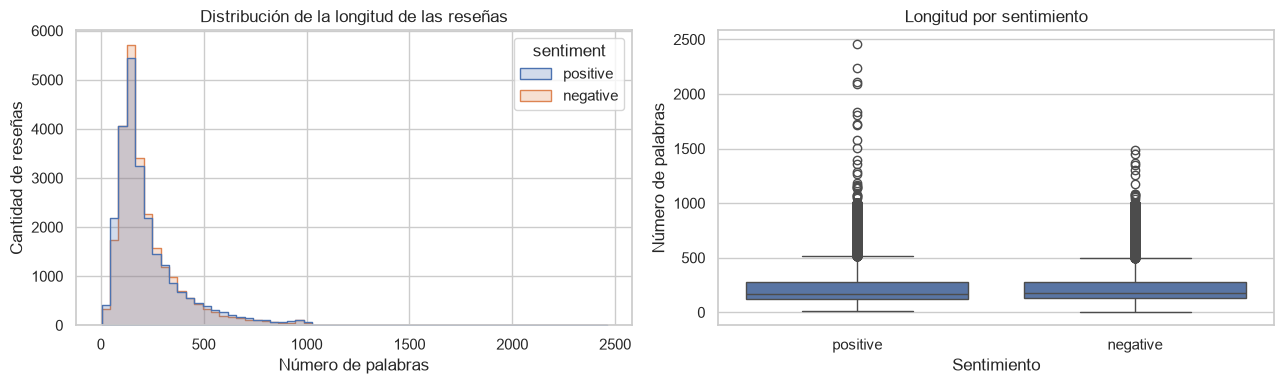

In [4]:
# Retirar HTML solo para contar las palabras.
# La columna review conserva el texto original.
texto_sin_html = datos["review"].str.replace(
    r"<[^>]+>", " ", regex=True
)

datos["longitud_palabras"] = texto_sin_html.str.split().str.len()

display(
    datos.groupby("sentiment")["longitud_palabras"]
    .describe()
    .round(2)
)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

sns.histplot(
    data=datos,
    x="longitud_palabras",
    hue="sentiment",
    bins=60,
    element="step",
    ax=axes[0]
)
axes[0].set_title("Distribución de la longitud de las reseñas")
axes[0].set_xlabel("Número de palabras")
axes[0].set_ylabel("Cantidad de reseñas")

sns.boxplot(
    data=datos,
    x="sentiment",
    y="longitud_palabras",
    ax=axes[1]
)
axes[1].set_title("Longitud por sentimiento")
axes[1].set_xlabel("Sentimiento")
axes[1].set_ylabel("Número de palabras")

plt.tight_layout()
plt.show()

### Análisis exploratorio

El conjunto original contiene 50 000 reseñas, distribuidas por igual entre
sentimientos positivos y negativos. No se encontraron valores nulos.
Se eliminaron 418 registros duplicados para reducir el riesgo de que una
misma reseña aparezca en entrenamiento y prueba.

Después de la depuración quedaron 49 582 reseñas: 24 884 positivas y
24 698 negativas. Por tanto, las clases siguen prácticamente balanceadas.

Las reseñas positivas tienen una longitud promedio de 230.86 palabras y
las negativas de 227.24. Las medianas son de 171 y 173 palabras,
respectivamente. Estos valores y la superposición de los histogramas
muestran que ambas clases presentan longitudes similares.

Las dos distribuciones presentan asimetría hacia la derecha: predominan
las reseñas relativamente cortas, pero existen algunas muy extensas.
La reseña positiva más larga contiene 2459 palabras y la negativa más
larga, 1491.

Se conservaron las reseñas extensas porque su longitud no implica que sean
datos incorrectos. La similitud entre las distribuciones sugiere que la
longitud por sí sola ofrece poca capacidad para distinguir el sentimiento;
por ello, analizaremos el contenido del texto.

## 2. Preprocesamiento del texto

In [5]:
#Seleccionamos 5000 reseñas
from sklearn.model_selection import train_test_split

muestra, _ = train_test_split(
    datos,
    train_size=5000,
    stratify=datos["sentiment"],
    random_state=42
)

muestra = muestra.reset_index(drop=True)

print("Tamaño de la muestra:", len(muestra))
display(muestra["sentiment"].value_counts())

Tamaño de la muestra: 5000


sentiment
positive    2509
negative    2491
Name: count, dtype: int64

In [6]:
#Inspeccion de reseñas
for i in range(3):
    print(f"\nRESEÑA {i + 1}")
    print("Sentimiento:", muestra.loc[i, "sentiment"])
    print(muestra.loc[i, "review"])
    print("-" * 80)


RESEÑA 1
Sentimiento: negative
This film reminds me a lot of the anti-drug films of the 50's and 60's due to the fact that it was made by people that have obviously never experienced the social evil that they are warning us about. Tom Hanks and his buddies are "role playing", but there are no dice, lots of candles, and then you are just swept away in a bad montage showing Hanks falling for the lady in the group. quite funny but misguided. I wonder how many poor kids had their D&D stuff destroyed, and were told that the use of their imagination was the road to destruction. As a film it's basically an after school special, bad acting (although Hanks does show some of his talent) and relationship talks, and no one seems to be having any fun. It seems these films have a psychological focus on adolescents starting on the road to adultism, which is more serious, apparently, and requires you to buckle down and do the things everyone else does. Despite my vote of 2, this is worth watching due

In [7]:
textos = muestra["review"]

elementos = {
    "Etiquetas HTML": r"<[^>]+>",
    "Entidades HTML": r"&(?:[A-Za-z]+|#\d+|#x[0-9A-Fa-f]+);",
    "Enlaces web": r"https?://\S+|www\.\S+",
    "Dígitos": r"\d",
    "Apóstrofos o contracciones": r"['’]"
}

for nombre, patron in elementos.items():
    cantidad = textos.str.contains(patron, regex=True, na=False).sum()
    print(f"{nombre}: {cantidad} reseñas")

Etiquetas HTML: 2917 reseñas
Entidades HTML: 0 reseñas
Enlaces web: 26 reseñas
Dígitos: 2813 reseñas
Apóstrofos o contracciones: 4428 reseñas


In [8]:
#Instalacion de NLTK
%pip install nltk

Note: you may need to restart the kernel to use updated packages.


In [9]:
#Prueba NLTK
import re
import nltk

from nltk.corpus import stopwords
from nltk.stem import PorterStemmer

nltk.download("stopwords")

# Conservar palabras relevantes para expresar negación y contraste.
palabras_conservar = {"no", "not", "nor", "but"}

stop_words = set(stopwords.words("english")) - palabras_conservar

stemmer = PorterStemmer()

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\EDDY\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [10]:
def preprocesar_texto(texto):
    # Minúsculas y normalización de apóstrofos.
    texto = texto.lower().replace("’", "'")

    # Retirar HTML y enlaces, presentes en la muestra.
    texto = re.sub(r"<[^>]+>", " ", texto)
    texto = re.sub(r"https?://\S+|www\.\S+", " ", texto)

    # Expandir contracciones para conservar las negaciones.
    texto = re.sub(r"\bwon't\b", "will not", texto)
    texto = re.sub(r"\bcan't\b", "can not", texto)
    texto = re.sub(r"\bshan't\b", "shall not", texto)
    texto = re.sub(r"n't\b", " not", texto)

    # Extraer palabras y números.
    # Los números se conservan porque pueden ser años o calificaciones.
    tokens = re.findall(r"[a-z]+|\d+(?:\.\d+)?", texto)

    # Eliminar stopwords y aplicar stemming.
    tokens_limpios = [
        stemmer.stem(token)
        for token in tokens
        if token not in stop_words
    ]

    return " ".join(tokens_limpios)

In [11]:
ejemplos = [
    "This movie is not good.",
    "I couldn't enjoy this movie.",
    "The actors are good, but the story is terrible."
]

for texto in ejemplos:
    print("Original:", texto)
    print("Procesado:", preprocesar_texto(texto))
    print()

Original: This movie is not good.
Procesado: movi not good

Original: I couldn't enjoy this movie.
Procesado: could not enjoy movi

Original: The actors are good, but the story is terrible.
Procesado: actor good but stori terribl



In [12]:
muestra["review_limpia"] = muestra["review"].apply(preprocesar_texto)

display(
    muestra[["review", "review_limpia", "sentiment"]].head()
)

vacias = muestra["review_limpia"].str.strip().eq("").sum()
print("Reseñas vacías después de limpiar:", vacias)

,review,review_limpia,sentiment
0,This film reminds me a lot of the anti-drug fi...,film remind lot anti drug film 50 60 due fact ...,negative
1,This movie is so stupid that I want my $2.99 b...,movi stupid want 2.99 back paid first movi sta...,negative
2,"I have a high tolerance for the weird, but fra...",high toler weird but frankli movi go way way b...,negative
3,"""Eh-heh eh-heh hey, dude - look at these alien...",eh heh eh heh hey dude look alien like bite hu...,negative
4,"Ill-tempered, verbally abusive movie studio ch...",ill temper verbal abus movi studio chief run m...,negative


Reseñas vacías después de limpiar: 0


### Preprocesamiento del texto

Se seleccionó una muestra de 5000 reseñas mediante muestreo estratificado
con random_state=42. La muestra contiene 2509 reseñas positivas y 2491
negativas, manteniendo aproximadamente la proporción del conjunto depurado.

La inspección identificó etiquetas HTML en 2917 reseñas, enlaces web en
26, dígitos en 2813 y apóstrofos o contracciones en 4428. No se encontraron
entidades HTML, por lo que no se añadió un tratamiento específico para ellas.

Se convirtieron los textos a minúsculas y se eliminaron las etiquetas HTML
y los enlaces. Se conservaron los números porque pueden representar años,
calificaciones u otros elementos del contenido.

Antes de retirar la puntuación, se expandieron las contracciones negativas
para conservar su significado. Por ejemplo, couldn't se transformó en
could not. Se eliminaron las stopwords de NLTK, exceptuando no, not, nor
y but, porque las negaciones y el contraste pueden modificar el sentimiento
de una oración. Eliminar not haría que expresiones como good y not good
quedaran representadas de manera similar.

Finalmente, se aplicó PorterStemmer para reducir variantes de palabras a
raíces comunes y disminuir la diversidad del vocabulario. Este proceso
puede perder algunos matices, y conservar las negaciones no garantiza que
un modelo basado en palabras aisladas interprete correctamente su contexto.

## 3. Division de datos 

In [13]:
#80% Entrenamiento 20% prueba 
from sklearn.model_selection import train_test_split

X = muestra["review_limpia"]
y = muestra["sentiment"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

print("Reseñas de entrenamiento:", len(X_train))
print("Reseñas de prueba:", len(X_test))

display(
    pd.DataFrame({
        "Entrenamiento": y_train.value_counts(),
        "Prueba": y_test.value_counts()
    })
)

Reseñas de entrenamiento: 4000
Reseñas de prueba: 1000


,Entrenamiento,Prueba
sentiment,,
positive,2007,502
negative,1993,498


### División de los datos

Se dividió la muestra en 80 % para entrenamiento y 20 % para prueba.
Se utilizó stratify para mantener aproximadamente la proporción de clases
en ambos conjuntos y random_state=42 para reproducir la división.

El vectorizador debe ajustarse únicamente con los textos de entrenamiento.
Durante fit aprende el vocabulario y, en TF-IDF, las frecuencias documentales.
Si se incluyeran las reseñas de prueba en este proceso, se incorporaría
información del conjunto reservado para evaluar, provocando fuga de datos.

Por ello, se utiliza fit_transform en entrenamiento y únicamente transform
en prueba.

## 4. Vectorización

In [14]:
#Bag of Words y TF-IDF
from sklearn.feature_extraction.text import (
    CountVectorizer,
    TfidfVectorizer
)

# Modelo A: conteo de palabras
vectorizador_bow = CountVectorizer(
    max_features=10000,
    min_df=2,
    ngram_range=(1, 1)
)

X_train_bow = vectorizador_bow.fit_transform(X_train)
X_test_bow = vectorizador_bow.transform(X_test)

# Modelo B: ponderación TF-IDF
vectorizador_tfidf = TfidfVectorizer(
    max_features=10000,
    min_df=2,
    ngram_range=(1, 1)
)

X_train_tfidf = vectorizador_tfidf.fit_transform(X_train)
X_test_tfidf = vectorizador_tfidf.transform(X_test)

print("Bag of Words:")
print("Entrenamiento:", X_train_bow.shape)
print("Prueba:", X_test_bow.shape)

print("\nTF-IDF:")
print("Entrenamiento:", X_train_tfidf.shape)
print("Prueba:", X_test_tfidf.shape)

Bag of Words:
Entrenamiento: (4000, 10000)
Prueba: (1000, 10000)

TF-IDF:
Entrenamiento: (4000, 10000)
Prueba: (1000, 10000)


### Representaciones del texto

#### Bag of Words

Bag of Words representa cada reseña mediante el número de veces que aparece
cada término del vocabulario. Considera la frecuencia de las palabras,
pero con unigramas no conserva su orden.

#### TF-IDF

TF-IDF combina la frecuencia de un término dentro de una reseña con una
ponderación que disminuye la importancia de los términos presentes en
muchas reseñas. Así, una palabra frecuente en un texto, pero poco común
en el conjunto de entrenamiento, puede recibir mayor peso.

#### Parámetros iniciales

Se estableció max_features=10000 para limitar el tamaño del vocabulario
y min_df=2 para excluir términos presentes en menos de dos reseñas de
entrenamiento. Inicialmente se utilizaron unigramas, mediante
ngram_range=(1, 1).

Ambas representaciones utilizan los mismos parámetros y la misma división
de datos para facilitar su comparación.

## 5. Entrenamiento y evaluación

In [15]:
from sklearn.linear_model import LogisticRegression

modelo_bow = LogisticRegression(
    max_iter=2000,
    random_state=42
)

modelo_tfidf = LogisticRegression(
    max_iter=2000,
    random_state=42
)

modelo_bow.fit(X_train_bow, y_train)
modelo_tfidf.fit(X_train_tfidf, y_train)

pred_bow = modelo_bow.predict(X_test_bow)
pred_tfidf = modelo_tfidf.predict(X_test_tfidf)

print("Ambos modelos fueron entrenados.")

Ambos modelos fueron entrenados.


### Metricas y tabla comparativa

In [16]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    ConfusionMatrixDisplay
)

def evaluar_modelo(nombre, y_real, y_pred):
    return {
        "Modelo": nombre,
        "Exactitud": accuracy_score(y_real, y_pred),
        "Precisión": precision_score(
            y_real, y_pred, pos_label="positive", zero_division=0
        ),
        "Recall": recall_score(
            y_real, y_pred, pos_label="positive", zero_division=0
        ),
        "F1": f1_score(
            y_real, y_pred, pos_label="positive", zero_division=0
        )
    }

resultados = pd.DataFrame([
    evaluar_modelo("Bag of Words", y_test, pred_bow),
    evaluar_modelo("TF-IDF", y_test, pred_tfidf)
])

display(resultados.round(4))

,Modelo,Exactitud,Precisión,Recall,F1
0,Bag of Words,0.838,0.8373,0.8406,0.8390
1,TF-IDF,0.847,0.8274,0.8785,0.8522


| Métrica | Qué indica |
|---|---|
| Exactitud | Proporción total de reseñas clasificadas correctamente |
| Precisión | De las predichas como positivas, cuántas realmente lo son |
| Recall | De las realmente positivas, cuántas detectó el modelo |
| F1 | Combina precisión y recall mediante su media armónica |

### Marices de Confusión

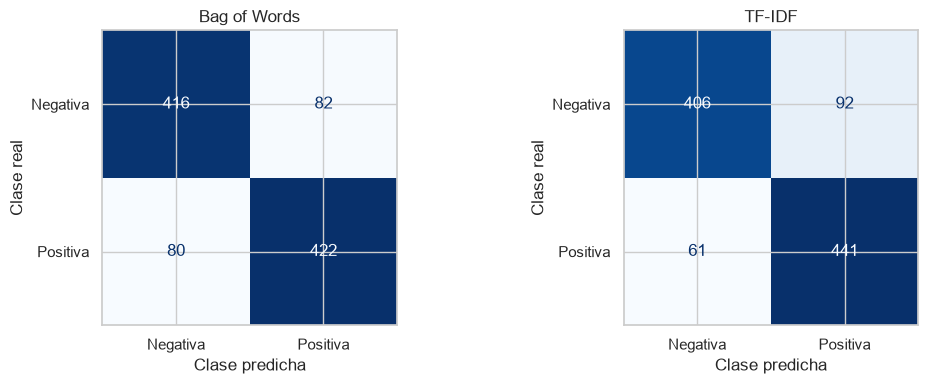

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

for ax, nombre, predicciones in [
    (axes[0], "Bag of Words", pred_bow),
    (axes[1], "TF-IDF", pred_tfidf)
]:
    ConfusionMatrixDisplay.from_predictions(
        y_test,
        predicciones,
        labels=["negative", "positive"],
        display_labels=["Negativa", "Positiva"],
        cmap="Blues",
        colorbar=False,
        ax=ax
    )

    ax.set_title(nombre)
    ax.set_xlabel("Clase predicha")
    ax.set_ylabel("Clase real")

plt.tight_layout()
plt.show()

| Resultado | Bag of Words | TF-IDF |
|---|---:|---:|
| Reseñas clasificadas correctamente | 838 | 847 |
| Negativas clasificadas como positivas | 82 | 92 |
| Positivas clasificadas como negativas | 80 | 61 |

### Evaluación inicial

Bag of Words alcanzó una exactitud de 83.8 % y un F1 de 0.8390.
TF-IDF obtuvo una exactitud de 84.7 % y un F1 de 0.8522.

TF-IDF identificó correctamente 441 de las 502 reseñas positivas,
mientras que Bag of Words identificó 422. Sin embargo, TF-IDF clasificó
incorrectamente 92 reseñas negativas como positivas, frente a 82
con Bag of Words. Esto explica su mayor recall y su menor precisión.

En esta comparación inicial, TF-IDF presenta un mejor equilibrio entre
precisión y recall según F1. La diferencia de exactitud es de 0.9 puntos
porcentuales, equivalente a nueve aciertos adicionales en las 1000 reseñas
de prueba. Estos resultados corresponden a una sola división de los datos
y no demuestran una superioridad universal.

In [18]:
#Comparacion unigramas con unigramas y bigramas
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import make_scorer

validacion = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

metricas = {
    "exactitud": "accuracy",
    "f1": make_scorer(f1_score, pos_label="positive")
}

experimentos = []

for nombre, clase_vectorizador in [
    ("Bag of Words", CountVectorizer),
    ("TF-IDF", TfidfVectorizer)
]:
    for ngramas in [(1, 1), (1, 2)]:

        pipeline = Pipeline([
            ("vectorizador", clase_vectorizador(
                max_features=10000,
                min_df=2,
                ngram_range=ngramas
            )),
            ("clasificador", LogisticRegression(
                max_iter=2000,
                random_state=42
            ))
        ])

        puntuaciones = cross_validate(
            pipeline,
            X_train,
            y_train,
            cv=validacion,
            scoring=metricas,
            n_jobs=1,
            error_score="raise"
        )

        experimentos.append({
            "Representación": nombre,
            "ngram_range": str(ngramas),
            "Exactitud media": puntuaciones["test_exactitud"].mean(),
            "F1 medio": puntuaciones["test_f1"].mean(),
            "Desviación F1": puntuaciones["test_f1"].std()
        })

tabla_experimentos = pd.DataFrame(experimentos)

display(
    tabla_experimentos.sort_values(
        "F1 medio", ascending=False
    ).round(4)
)

,Representación,ngram_range,Exactitud media,F1 medio,Desviación F1
3,TF-IDF,"(1, 2)",0.8515,0.8539,0.0043
2,TF-IDF,"(1, 1)",0.8490,0.8526,0.0050
1,Bag of Words,"(1, 2)",0.8458,0.8478,0.0023
0,Bag of Words,"(1, 1)",0.8380,0.8397,0.0014


### Experimento con ngram_range y selección del modelo

Se compararon unigramas (1, 1) con unigramas y bigramas (1, 2),
manteniendo max_features=10000 y min_df=2. Se utilizó validación cruzada
estratificada de tres particiones únicamente sobre entrenamiento.

Los bigramas aumentaron el F1 medio de Bag of Words de 0.8397 a 0.8478
y el de TF-IDF de 0.8526 a 0.8539. Esto sugiere que incorporar pares
consecutivos de palabras puede aportar información útil sobre expresiones
como not good. Las mejoras se observaron con un vocabulario limitado
a 10 000 términos.

Se seleccionó TF-IDF con ngram_range=(1, 2) por alcanzar el mayor F1 medio
de validación. Sin embargo, su ventaja frente a TF-IDF con unigramas fue
pequeña y menor que la variación entre particiones; por ello, no se puede
afirmar que la mejora sea concluyente.

,Modelo,Exactitud,Precisión,Recall,F1
0,TF-IDF + unigramas y bigramas,0.848,0.8277,0.8805,0.8533


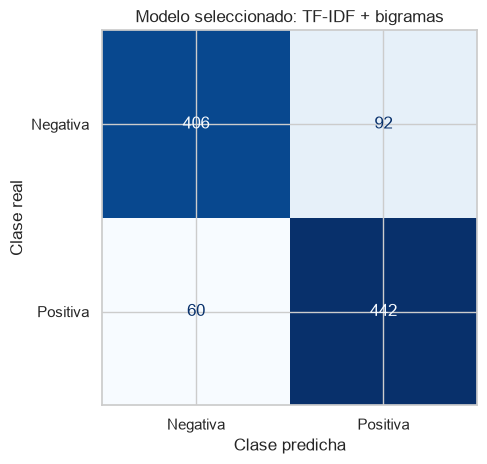

In [19]:
mejor_pipeline = Pipeline([
    ("vectorizador", TfidfVectorizer(
        max_features=10000,
        min_df=2,
        ngram_range=(1, 2)
    )),
    ("clasificador", LogisticRegression(
        max_iter=2000,
        random_state=42
    ))
])

mejor_pipeline.fit(X_train, y_train)

pred_final = mejor_pipeline.predict(X_test)

resultado_final = pd.DataFrame([
    evaluar_modelo(
        "TF-IDF + unigramas y bigramas",
        y_test,
        pred_final
    )
])

display(resultado_final.round(4))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    pred_final,
    labels=["negative", "positive"],
    display_labels=["Negativa", "Positiva"],
    cmap="Blues",
    colorbar=False
)

plt.title("Modelo seleccionado: TF-IDF + bigramas")
plt.xlabel("Clase predicha")
plt.ylabel("Clase real")
plt.tight_layout()
plt.show()

### Evaluación del modelo seleccionado

Se seleccionó TF-IDF con unigramas y bigramas por obtener el mayor F1
medio en validación cruzada sobre entrenamiento.

Al evaluarlo sobre las 1000 reseñas de prueba, alcanzó una exactitud de
84.8 %, precisión de 0.8277, recall de 0.8805 y F1 de 0.8533.
Clasificó correctamente 406 reseñas negativas y 442 positivas.
Los errores fueron 92 reseñas negativas predichas como positivas y
60 positivas predichas como negativas.

La mejora frente a TF-IDF con unigramas fue pequeña: un acierto adicional.
Por tanto, los bigramas aportaron una mejora limitada en este experimento.



## 6. Interpretación del modelo

In [20]:
vectorizador_final = mejor_pipeline.named_steps["vectorizador"]
clasificador_final = mejor_pipeline.named_steps["clasificador"]

print("Orden de las clases:", clasificador_final.classes_)

coeficientes = pd.Series(
    clasificador_final.coef_[0],
    index=vectorizador_final.get_feature_names_out()
)

terminos_positivos = coeficientes.nlargest(15)
terminos_negativos = coeficientes.nsmallest(15)

tabla_coeficientes = pd.DataFrame({
    "Término positivo": terminos_positivos.index,
    "Coeficiente positivo": terminos_positivos.values,
    "Término negativo": terminos_negativos.index,
    "Coeficiente negativo": terminos_negativos.values
})

display(tabla_coeficientes.round(4))

Orden de las clases: ['negative' 'positive']


,Término positivo,Coeficiente positivo,Término negativo,Coeficiente negativo
0,great,4.1461,bad,-4.5330
1,love,2.9988,worst,-3.5833
2,enjoy,2.5867,no,-3.0272
3,excel,2.3309,aw,-2.9621
4,best,2.2386,would,-2.6513
5,well,2.2357,bore,-2.6506
6,perform,2.1115,stupid,-2.6262
7,also,2.0727,not,-2.5488
8,beauti,2.0382,wast,-2.4263
9,brilliant,1.8493,terribl,-2.3677


### Interpretación de los coeficientes

Los términos great, love, enjoy, best y recommend presentan coeficientes
positivos, coherentes con expresiones de satisfacción. Por su parte,
bad, worst, bore, stupid y terribl presentan coeficientes negativos,
relacionados con críticas desfavorables.

Algunos términos aparecen como raíces debido al stemming. Por ejemplo,
beauti puede proceder de beautiful y terribl de terrible.

Los términos no y not tienen coeficientes negativos, lo que muestra una
asociación con reseñas negativas en los datos de entrenamiento. Sin embargo,
una negación no siempre expresa una opinión negativa: not bad puede
transmitir una valoración favorable.

Palabras como also, world, would y plot no tienen un sentimiento fijo.
Sus coeficientes reflejan asociaciones aprendidas en este conjunto de
datos, no significados universales ni relaciones causales.

Cada coeficiente indica cómo cambia la puntuación del modelo al aumentar
el valor TF-IDF del término, manteniendo las otras características fijas.
El efecto en la predicción depende tanto del coeficiente como del valor
TF-IDF presente en la reseña.

In [21]:
#Prediccion de 3 reseñas nuevas
resenas_propias = pd.DataFrame({
    "Tipo": ["Positiva", "Negativa", "Sarcástica"],
    "Reseña": [
        "I loved this movie. The performances were excellent "
        "and the story was beautiful. I highly recommend it.",

        "This movie was terrible. The acting was bad, "
        "the story was boring, and watching it was a waste of time.",

        "What a brilliant movie! I especially loved checking "
        "the clock every two minutes and waiting for it to end."
    ]
})

# Aplicar exactamente el mismo preprocesamiento.
textos_propios = resenas_propias["Reseña"].apply(preprocesar_texto)

resenas_propias["Predicción"] = mejor_pipeline.predict(textos_propios)

probabilidades = mejor_pipeline.predict_proba(textos_propios)

# Asociar cada probabilidad con su clase usando classes_.
for posicion, clase in enumerate(clasificador_final.classes_):
    resenas_propias[f"P({clase})"] = probabilidades[:, posicion]

display(resenas_propias.round(4))

,Tipo,Reseña,Predicción,P(negative),P(positive)
0,Positiva,I loved this movie. The performances were exce...,positive,0.0084,0.9916
1,Negativa,"This movie was terrible. The acting was bad, t...",negative,0.9523,0.0477
2,Sarcástica,What a brilliant movie! I especially loved che...,positive,0.2388,0.7612


### Predicción de reseñas nuevas

La reseña positiva fue clasificada correctamente con una probabilidad
positiva de 99.16 %. La reseña negativa también fue clasificada
correctamente, con una probabilidad negativa de 95.23 %. Esto muestra
que el modelo reconoce estos ejemplos con opiniones explícitas.

La reseña sarcástica fue clasificada como positiva con una probabilidad
de 76.12 %, aunque expresa una crítica: la persona revisaba el reloj
constantemente y esperaba que terminara la película.

Una posible explicación es que expresiones como brilliant y loved
aportaron señales positivas, mientras que el modelo no logró interpretar
la intención irónica del resto de la oración. TF-IDF con unigramas y
bigramas representa términos y pares de palabras, pero no comprende
necesariamente el significado global ni el sarcasmo.

Las probabilidades son estimaciones del modelo y no garantizan que
su interpretación sea correcta.

In [22]:
#Identificador de dos reseñas mal clasificadas 
evaluacion = pd.DataFrame({
    "Reseña original": muestra.loc[X_test.index, "review"],
    "Clase real": y_test,
    "Predicción": pred_final
})

prob_test = mejor_pipeline.predict_proba(X_test)

for posicion, clase in enumerate(clasificador_final.classes_):
    evaluacion[f"P({clase})"] = prob_test[:, posicion]

errores = evaluacion[
    evaluacion["Clase real"] != evaluacion["Predicción"]
]

print("Total de errores:", len(errores))

# Mostrar un error de cada clase real, si existen ambos.
dos_errores = pd.concat([
    errores[errores["Clase real"] == "negative"].head(1),
    errores[errores["Clase real"] == "positive"].head(1)
])

for indice, fila in dos_errores.iterrows():
    print(f"\nÍNDICE: {indice}")
    print("Clase real:", fila["Clase real"])
    print("Predicción:", fila["Predicción"])
    print(f"P(negative): {fila['P(negative)']:.4f}")
    print(f"P(positive): {fila['P(positive)']:.4f}")
    print("\nReseña original:")
    print(fila["Reseña original"])
    print("-" * 80)

Total de errores: 152

ÍNDICE: 2353
Clase real: negative
Predicción: positive
P(negative): 0.4314
P(positive): 0.5686

Reseña original:
I have been using IMDb for years and I never wanted to get involved in the commentary of moviesuntil now. This documentary has so many problems that I hardly know what to say. I am not a Muslim, nor am I an Islamic studies expert, but I know enough to shed some light on the obvious one-sided viewpoint that this documentary espouses. <br /><br />The problems with this movie begin with the fact that it is a documentary. Most of the documentaries that I have seen anchor themselves around a few valid points and then surround those points with debatable interpretations and misinformation. This is certainly the case with Islam: What the West Needs to Know. Yes, there are fundamentalists around the world, and some of them are Muslim, but to build a documentary about all of Islam around a small percentage of radicalized people is incredibly misleading. This i

### Análisis de dos errores de clasificación

El modelo cometió 152 errores entre las 1000 reseñas de prueba.
Se analizaron dos casos, uno de cada tipo de error.

#### Caso 1: reseña negativa clasificada como positiva — índice 2353

El modelo asignó una probabilidad positiva de 56.86 %. Se trata de un
falso positivo, considerando positive como la clase positiva.

La reseña critica la falta de objetividad de un documental. Sin embargo,
gran parte del texto desarrolla argumentos sobre religión, traducciones
y contexto histórico, en lugar de utilizar expresiones habituales de
crítica cinematográfica.

Una posible causa del error es la dificultad para distinguir las
opiniones sobre el documental de las afirmaciones sobre el tema que
este aborda. Además, aparecen palabras favorables dentro de negaciones
o explicaciones que no expresan aprobación de la película.

La probabilidad cercana al 50 % indica que la decisión estuvo próxima
al umbral de clasificación. Esta explicación es una hipótesis basada
en la lectura; no se calcularon las contribuciones individuales de
los términos de esta reseña.

#### Caso 2: reseña positiva clasificada como negativa — índice 259

El modelo asignó una probabilidad negativa de 65.73 %. Se trata de un
falso negativo.

La persona valora positivamente la película, pero critica la calidad
de la edición en DVD, especialmente el sonido y la restauración.
Al final distingue claramente ambos aspectos: otorga 9 de 10 a la
película y 5 al producto.

El modelo posiblemente interpretó las críticas al DVD como una opinión
negativa sobre la película. Aunque existen elogios, el texto contiene
numerosas quejas relacionadas con la presentación del producto.

Este caso muestra la dificultad de un clasificador de sentimiento global
para distinguir valoraciones dirigidas a diferentes aspectos dentro
de una misma reseña.

## 7. Conclusiones

En este trabajo se aplicó un proceso de clasificación de sentimiento
a reseñas de películas en inglés. Se exploraron los datos, se eliminaron
418 registros duplicados y se seleccionó una muestra estratificada
de 5000 reseñas para realizar los experimentos.

El preprocesamiento eliminó etiquetas HTML y enlaces, conservó negaciones
y aplicó stemming. Estas decisiones permitieron reducir variaciones
del texto sin eliminar algunas palabras relevantes para el sentimiento.

Se compararon Bag of Words y TF-IDF con Regresión Logística. Además,
se experimentó con unigramas y bigramas mediante validación cruzada
sobre entrenamiento. TF-IDF con unigramas y bigramas obtuvo el mayor
F1 medio de validación y fue seleccionado como modelo final.

En prueba, el modelo alcanzó 84.8 % de exactitud y un F1 de 0.8533,
clasificando correctamente 848 de las 1000 reseñas. La mejora frente
a TF-IDF con unigramas fue pequeña, por lo que no puede afirmarse
que los bigramas produzcan una ventaja importante en este experimento.

Los coeficientes mostraron asociaciones coherentes, como great y love
con opiniones positivas, y bad y worst con negativas. Sin embargo,
las pruebas también evidenciaron dificultades con el sarcasmo,
las negaciones y las opiniones sobre distintos aspectos de un producto.

Como aprendizaje principal, comprendí que clasificar sentimiento
requiere considerar tanto la preparación de los datos como las
limitaciones de la representación del texto. Como trabajo futuro,
se podría ampliar la muestra y evaluar representaciones que incorporen
más contexto.

El conjunto de prueba ya se utilizó para comparar los modelos, por lo
que estos resultados deben entenderse como una evaluación del ejercicio.
Cualquier ajuste adicional debería realizarse con entrenamiento y
validación, reservando nuevos datos para una evaluación independiente.